In [ ]:
import numpy as np
from scipy.stats import norm
from matplotlib import colors

import jax.numpy as jnp
from jax import jit
from functools import partial

from pyCRLD.Agents.Base import abase
from pyCRLD.Utils.Helpers import *

In [ ]:
from pyCRLD.Agents.StrategyActorCritic import stratAC
from pyCRLD.Environments.EcologicalPublicGood import EcologicalPublicGood
from pyCRLD.Utils import FlowPlot as fp

import numpy as np
import itertools as it
import matplotlib.pyplot as plt
from pyCRLD.Utils.Helpers import compute_stationarydistribution

from datetime import datetime

In [ ]:
from DistBase import distbase

In [ ]:
# Define environment
env = EcologicalPublicGood(N=2, f=1.2, c=5, m=-4, qc=0.2, qr=0.1, degraded_choice=True)
env

EcologicalPublicGood_2_1.2_5_-4_0.2_0.1_DegChoi

In [ ]:
# Init enviornment and MultiAgentEnvironment-interface
mae = stratAC(env=env, learning_rates=0.1, discount_factors=0.9, use_prefactor=True)

In [ ]:
db = distbase(env, nr_reward_bins=21, discretization_sigma=0.25, learning_rates=0.1, discount_factors=0.9)

In [ ]:
def compute_errors(n_s, s):
    X1 = np.linspace(0, 1, n_s)
    X2 = np.linspace(0, 1, n_s)
    errors = np.zeros((2, n_s, n_s))
    for i, x1 in enumerate(X1):
        for j, x2 in enumerate(X2):
            Xisa = np.zeros((2, 2, 2))
            Xisa[0, :, 0] = x1
            Xisa[1, :, 0] = x2
            Xisa[0, :, 1] = 1 - x1
            Xisa[1, :, 1] = 1 - x2
            distRPE = db.RPEisa(Xisa, norm=True)
            aveRPE = mae.RPEisa(Xisa, norm=True)
            errors[0, i, j] = aveRPE[0, s, 0] - distRPE[0, s, 0]
            errors[1, i, j] = aveRPE[1, s, 0] - distRPE[1, s, 0]
    return errors

In [ ]:
errors_degraded = compute_errors(11, 0)
errors_prosperous = compute_errors(11, 1)

In [ ]:
def plot_errors(errors):
    fig, axes = plt.subplots(1, 2, figsize=(10, 3))
    for i, ax in enumerate(axes):
        errors = np.nan_to_num(errors, nan=10)
        mask = errors == 10
        vmax = np.max(np.abs(errors[~mask]))
        vmin = -vmax
        divnorm = colors.TwoSlopeNorm(vmin=vmin, vcenter=0, vmax=vmax)
        im = ax.imshow(errors[i, :, :], norm=divnorm, cmap="RdBu_r")
        ax.invert_yaxis()
        ax.set_title("Agent "+str(i))
        cbar = ax.figure.colorbar(im, ax=ax)
    fig.tight_layout()
    plt.show()

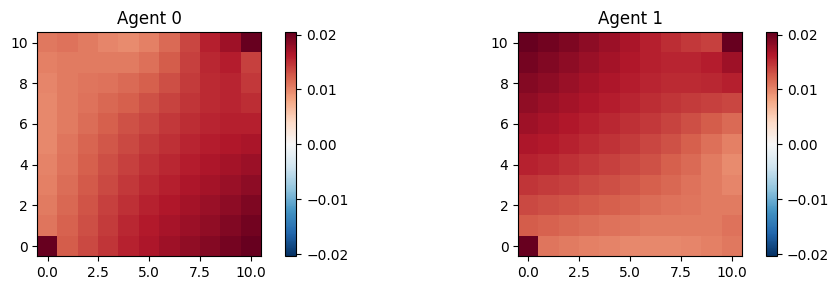

In [ ]:
plot_errors(errors_prosperous)

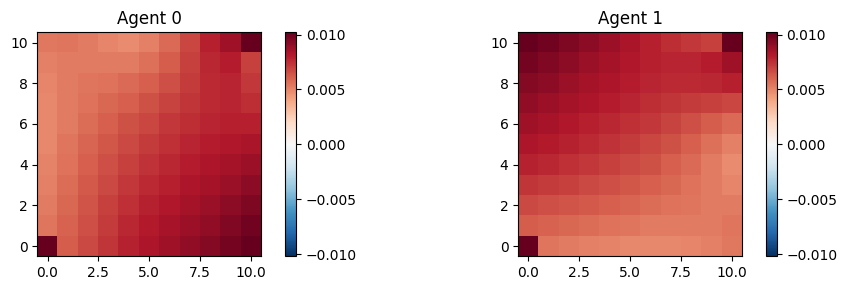

In [ ]:
plot_errors(errors_degraded)

In [ ]:
errors_prosperous[0, 4, 4]

0.018394984304904938

In [ ]:
Xisa = np.